# Marketing customer segmentation

Discover unlabeled customer groups using K-Means and Agglomerative clustering. No response labels enter training.

## Dataset, EDA and preprocessing
The marketing file is delimiter-detected (the supplied copy is tab-separated). IDs, constant fields and campaign outcome columns are excluded from fitting. Total spend, purchase count and customer tenure are deterministic summaries. Age uses the dataset's latest customer-registration year; implausible ages become missing. Median imputation and IQR clipping reduce extreme numeric influence, StandardScaler puts distances on comparable scales, and categoricals are one-hot encoded. All methods use the same transformed unlabeled cohort. Outcome response is inspected only after fitting.

Unsupervised fitting uses the full cohort. Five-fold subset refits independently fit preprocessing and measure metric/stability variation; these are explicitly not supervised held-out prediction CV. PCA and t-SNE are visualizations only; metrics use the complete transformed feature space.

Shape: (2240, 29) | Exact duplicates: 0
Implausible ages set missing: 3
Cleaned rows: 2058 | Clustering features: ['Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Age', 'Customer_Tenure_Days', 'Total_Spend', 'Total_Purchases'] | Matrix: (2058, 23)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


,dtype,missing
ID,int64,0
Year_Birth,int64,0
Education,str,0
Marital_Status,str,0
Income,float64,24
Kidhome,int64,0
Teenhome,int64,0
Dt_Customer,str,0
Recency,int64,0
MntWines,int64,0


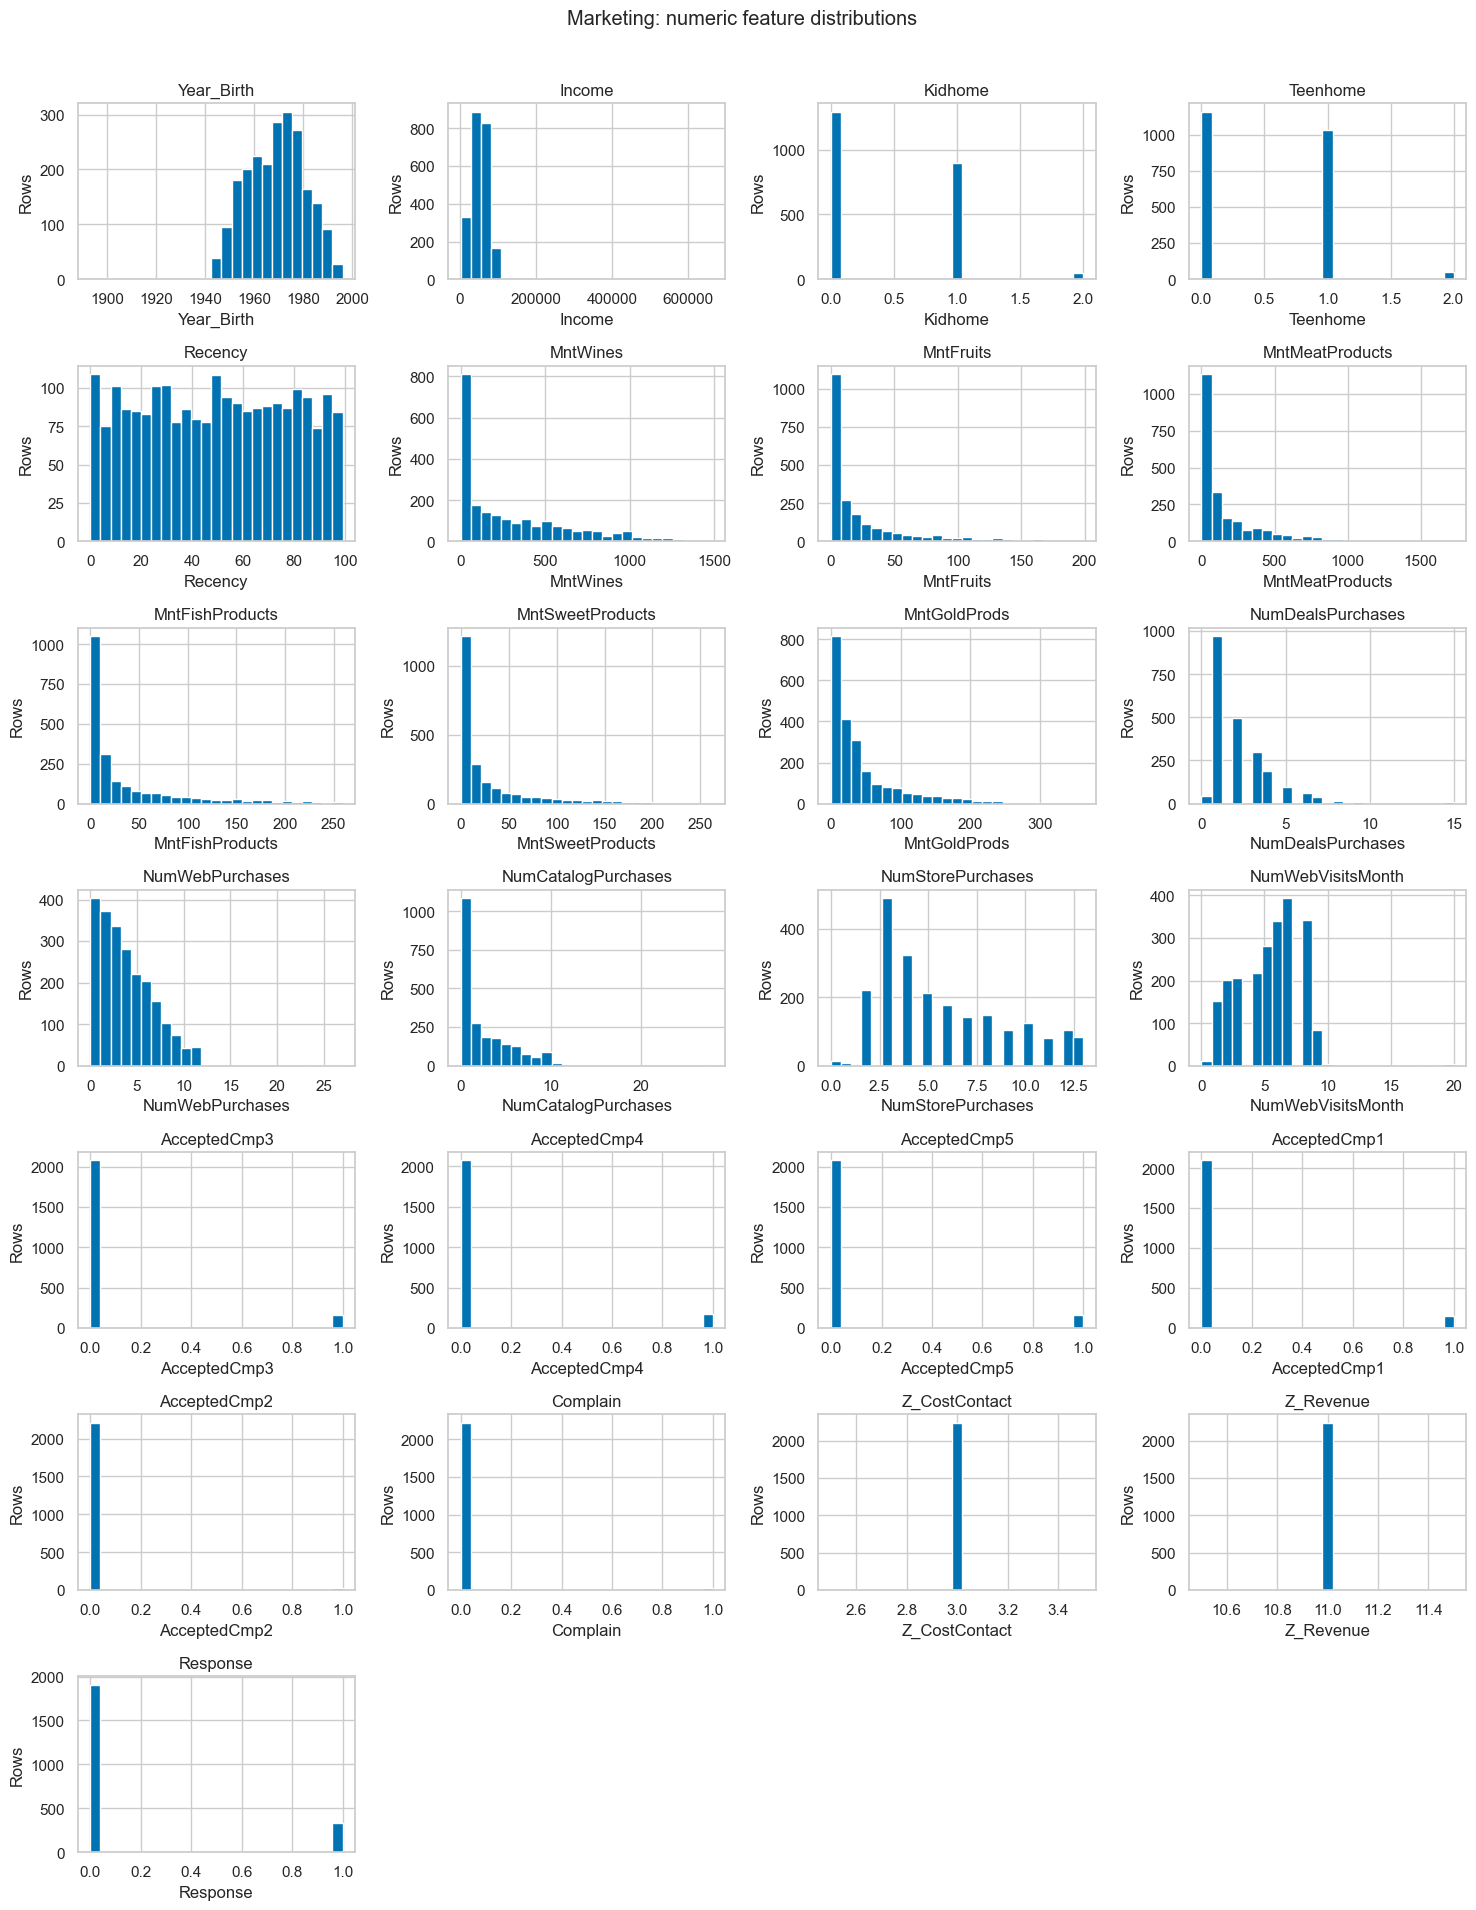

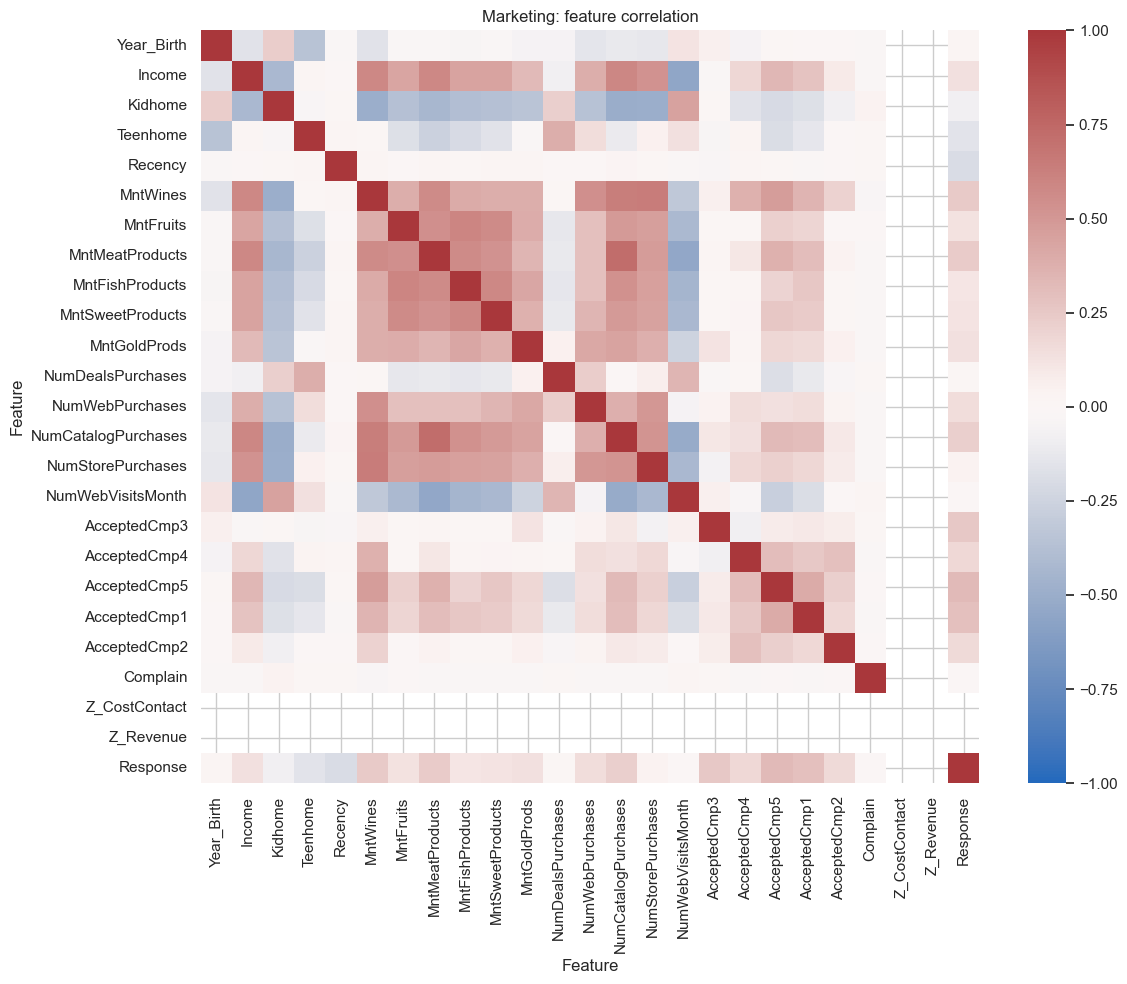

,IQR outliers (clipped in pipeline)
Income,8
Kidhome,0
Teenhome,0
Recency,0
NumDealsPurchases,78
NumWebVisitsMonth,8
Age,0
Customer_Tenure_Days,0
Total_Spend,3
Total_Purchases,0


In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'r2' / 'review2_pipeline.py').is_file())
sys.path.insert(0, str(root / 'r2'))
import review2_pipeline as review

data = review.marketing_data(show_eda=True)

## K-Means: elbow and fit
Select k with the maximum deviation from the normalized inertia chord (a reproducible geometric knee). Inspect the elbow before accepting it as a business choice. Evaluate silhouette (higher), Davies-Bouldin (lower), Calinski-Harabasz (higher), PCA, t-SNE and profiles.

Cluster sizes: [842, 668, 548] | k selected by geometric knee, independent of outcome labels.
PCA total explained variance: 0.4669102021817136
Unsupervised five-fold refit/stability check on 80% subsets, not held-out prediction accuracy. Hierarchical clustering has no predict method.


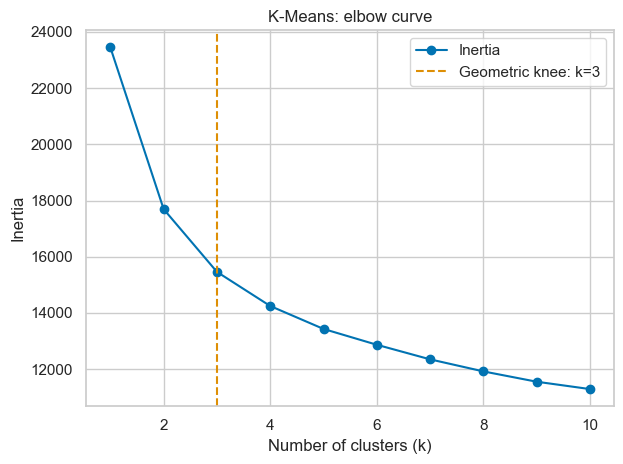

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,3,0.19033,1.81203,530.71243


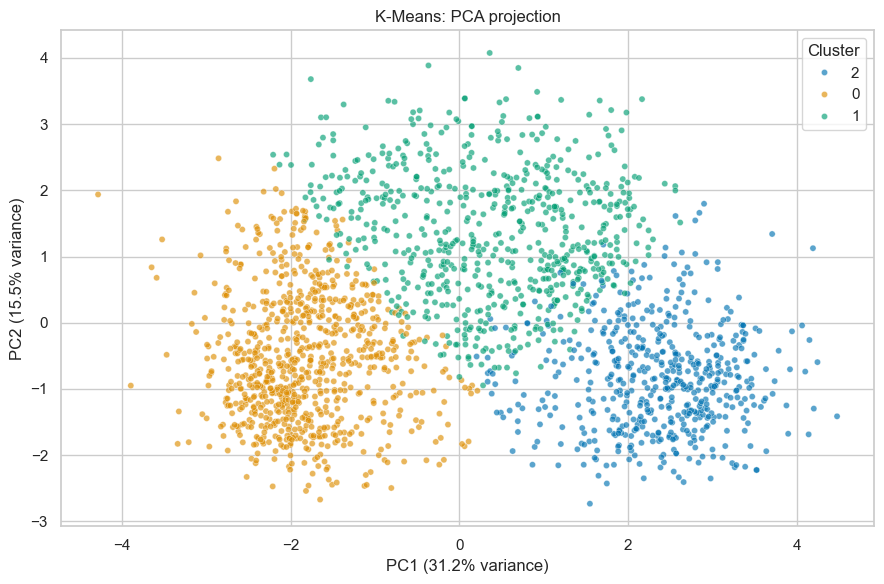

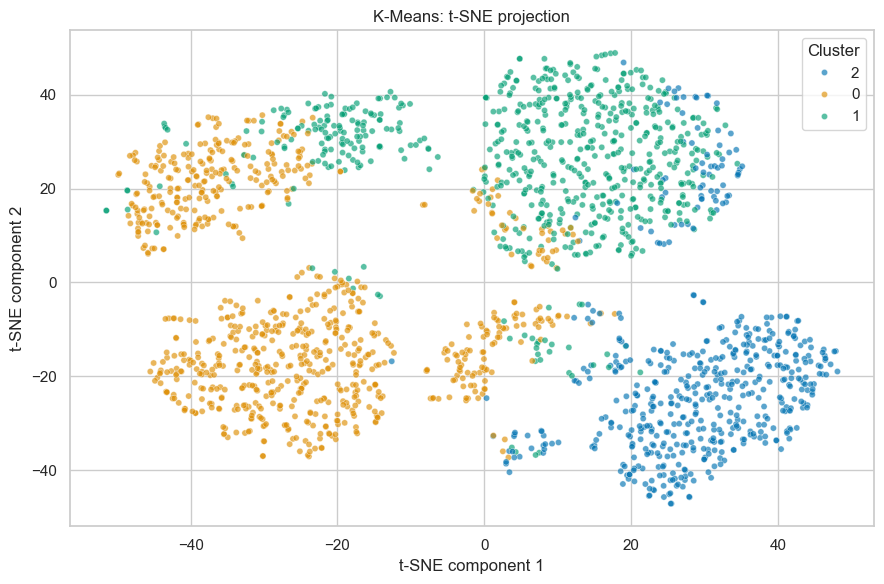

,Customers,Income,Age,Total_Spend,Total_Purchases,Recency
Cluster,,,,,,
0,842,32670.38,40.50,96.69,5.78,49.05
1,668,57232.43,50.55,655.48,15.58,48.45
2,548,76643.14,45.55,1329.14,19.19,49.41


Response,0,1
Cluster,,
0,0.900238,0.099762
1,0.881737,0.118263
2,0.726277,0.273723


,Algorithm,Fold,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,ARI_vs_full_fit
0,K-Means,1,0.1910,1.8104,425.6331,0.9708
1,K-Means,2,0.1937,1.7921,429.7393,0.9648
2,K-Means,3,0.1884,1.8208,419.2701,0.9603
3,K-Means,4,0.1920,1.8082,428.5047,0.9703
4,K-Means,5,0.1875,1.8214,421.4384,0.9838


In [2]:
kmeans_result = review.run_kmeans(data)

## Agglomerative clustering: dendrogram and linkage comparison
Use the same k as the K-Means elbow; compare Ward, complete and average linkages. Full-cohort dendrograms are truncated to the last 30 merged groups for readability. A minimum 2% cluster size rejects trivial outlier-only solutions; among remaining candidates select highest silhouette. Inspect all three metrics and the dendrogram before writing the final interpretation.

Selection rule: minimum cluster size >=2% of cohort, then highest silhouette. Selected: ward
PCA total explained variance: 0.4669102021817136
Unsupervised five-fold refit/stability check on 80% subsets, not held-out prediction accuracy. Hierarchical clustering has no predict method.


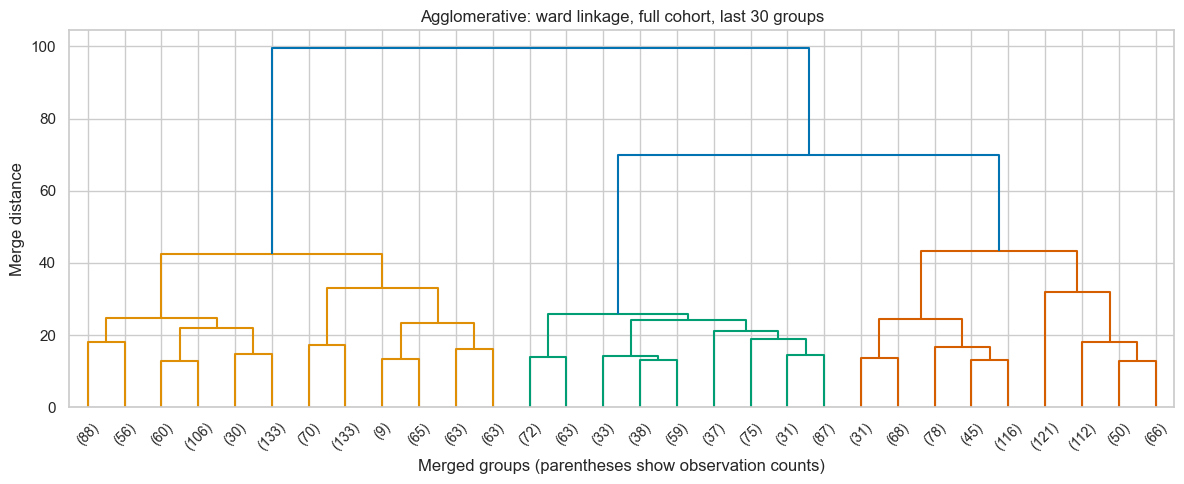

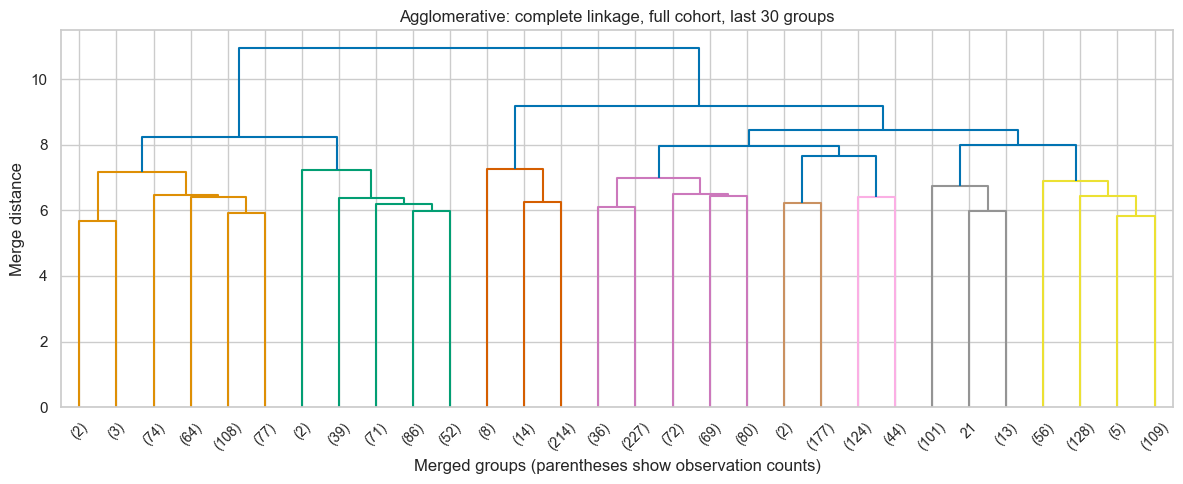

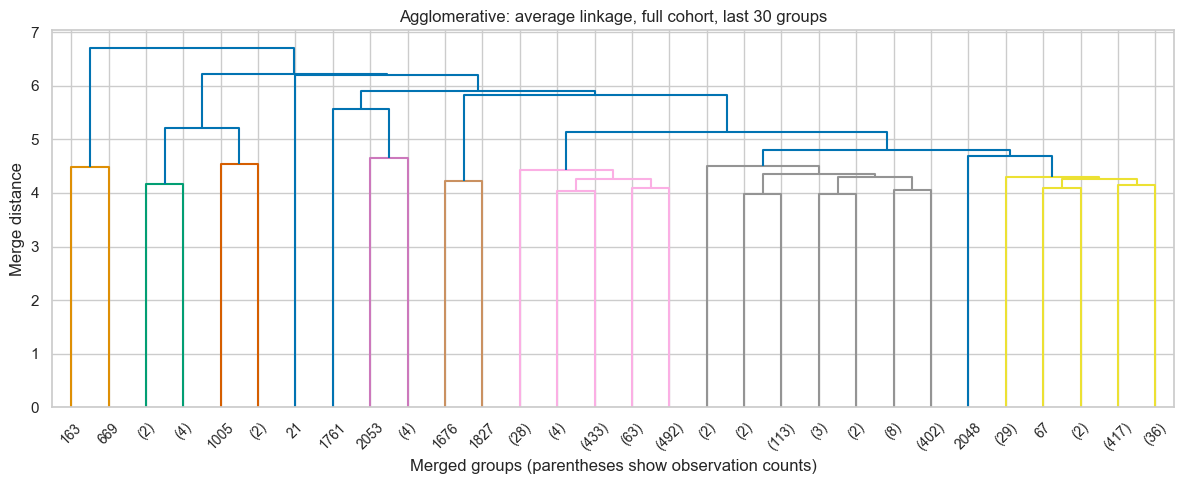

,Linkage,Clusters,Minimum_cluster_size,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,3,495,0.17339,1.90631,473.79480
1,complete,3,236,0.07307,2.14222,306.39436
2,average,3,2,0.14925,1.29128,10.45556


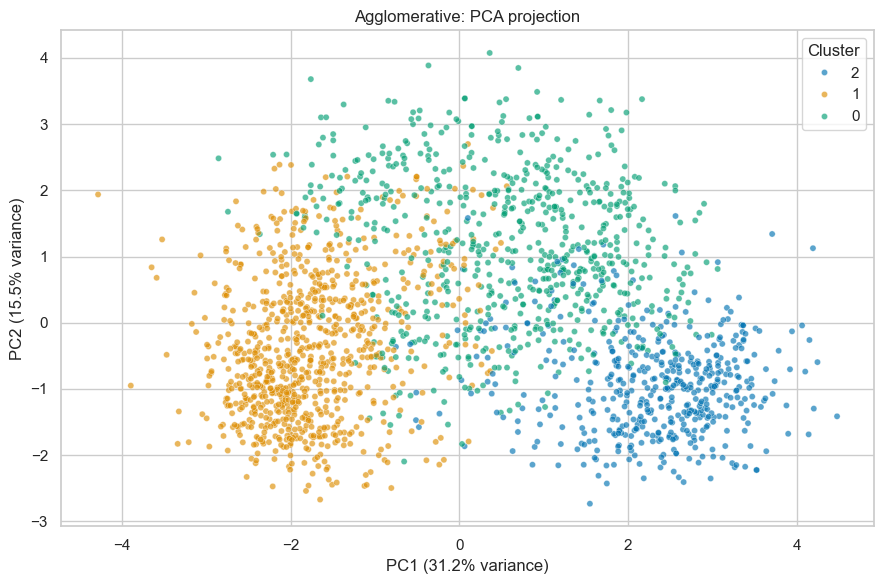

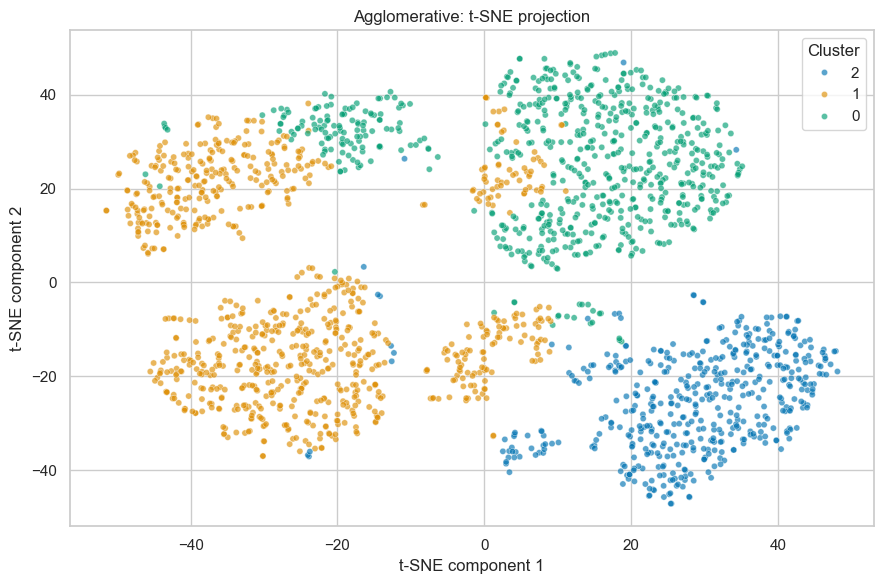

,Customers,Income,Age,Total_Spend,Total_Purchases,Recency
Cluster,,,,,,
0,687,58399.20,49.96,690.24,15.77,51.84
1,876,33444.10,41.26,123.30,6.35,47.11
2,495,77425.51,45.19,1344.32,18.97,48.21


Response,0,1
Cluster,,
0,0.899563,0.100437
1,0.893836,0.106164
2,0.694949,0.305051


,Algorithm,Fold,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,ARI_vs_full_fit
0,Agglomerative,1,0.1733,1.8717,381.1102,0.7001
1,Agglomerative,2,0.1657,1.9180,366.3855,0.6938
2,Agglomerative,3,0.1711,1.9342,374.9616,0.7067
3,Agglomerative,4,0.1640,1.8777,358.6810,0.5758
4,Agglomerative,5,0.1752,1.9057,384.4506,0.7067


In [3]:
agglomerative_result = review.run_agglomerative(data)

## Comparison of both required algorithms

In [4]:
clustering_comparison = review.consolidate_clustering()

,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Linkage
0,K-Means,3,0.19033,1.81203,530.71243,NaN
1,Agglomerative,3,0.17339,1.90631,473.79480,ward


## Team-written interpretation required before submission
The guidelines (section 7.5) permit AI code scaffolding but reserve analysis and interpretation for the team. Write your own observations here after studying the visible outputs. This cell deliberately does not supply an AI-written interpretation.

- Explain the major plots, errors or overlapping segments using the actual evidence above.
- Discuss the selected hyperparameters, metric trade-offs and limitations.
- For classification, explain weighted precision/recall/F1, ROC-AUC, the confusion matrix, and whether tuning improved any metric.
- For clustering, justify k/linkage using the elbow/dendrogram and all three metrics; explain profiles in original units and projection limitations.

**Submission status: team interpretation is pending until these points are replaced with original observations.**